# Visualise KIT-ML joints
Loads a processed clip from `dataset/KIT-ML`, decodes the 251-d features back to xyz, and plots the skeleton, root path and feature layout.

In [9]:
import os, sys, random
from pathlib import Path

# run from the repo root so `utils` resolves to the top-level package (not visualization/utils)
if Path.cwd().name == "visualization":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, os.getcwd())

import numpy as np, torch
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from utils.motion_process import recover_from_ric
from utils.paramUtil import kit_kinematic_chain as CHAIN

ROOT, J, FPS = Path("dataset/KIT-ML"), 21, 12.5
ids = [l.strip() for l in open(ROOT / "test.txt")]
print(len(ids), "test clips")

830 test clips


## 1. Load one clip
`new_joint_vecs/<id>.npy` is `[T, 251]` (raw, not z-normalised). `new_joints/<id>.npy` is the same clip already decoded to `[T, 21, 3]`.

In [10]:
cid = random.choice(ids)            # or set e.g. cid = "00001"
vec = np.load(ROOT / "new_joint_vecs" / f"{cid}.npy")
caps = [l.split("#")[0] for l in open(ROOT / "texts" / f"{cid}.txt")]
print(cid, "vec", vec.shape, "| captions:", caps)

# decode features -> xyz (root path is integrated from velocities)
xyz = recover_from_ric(torch.from_numpy(vec).float(), J).numpy()      # [T, 21, 3]
ref = np.load(ROOT / "new_joints" / f"{cid}.npy")
print("xyz", xyz.shape, "| max diff vs new_joints:", np.abs(xyz - ref).max())

02107 vec (147, 251) | captions: ['the person is first showing two hands and then kneeling down with the support of two hands', 'Someone is kneeling down.']
xyz (147, 21, 3) | max diff vs new_joints: 0.0


## 2. Skeleton snapshots
Y is up. Colours are the 5 kinematic chains (leg, leg, spine, arm, arm).

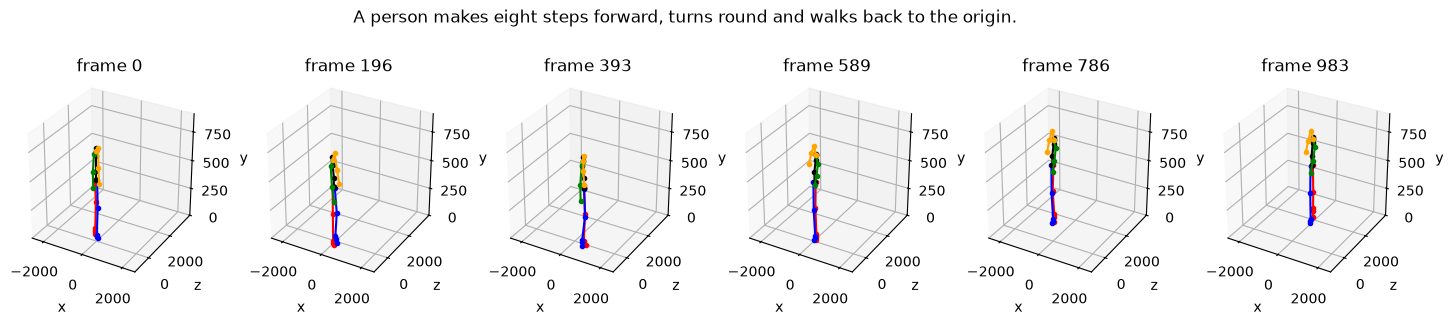

In [3]:
def draw(ax, p, lim):
    for c, col in zip(CHAIN, ["r", "b", "k", "g", "orange"]):
        ax.plot(p[c, 0], p[c, 2], p[c, 1], "-o", c=col, ms=3)   # plot as (x, z, y) so y is vertical
    ax.set_xlim(lim[0]); ax.set_ylim(lim[1]); ax.set_zlim(0, lim[2]); ax.set_box_aspect((1, 1, 1))
    ax.set_xlabel("x"); ax.set_ylabel("z"); ax.set_zlabel("y")

def limits(x):
    m, r = x[:, 0].mean(0), max(np.ptp(x[..., 0]), np.ptp(x[..., 2]), 1e-3) / 2
    return (m[0] - r, m[0] + r), (m[2] - r, m[2] + r), x[..., 1].max() * 1.05

lim = limits(xyz)
frames = np.linspace(0, len(xyz) - 1, 6).astype(int)
fig = plt.figure(figsize=(18, 3.5))
for i, f in enumerate(frames):
    ax = fig.add_subplot(1, 6, i + 1, projection="3d"); draw(ax, xyz[f], lim); ax.set_title(f"frame {f}")
plt.suptitle(caps[0]); plt.show()

## 3. Root trajectory and height
Top-down path of the root joint (joint 0) and its height over time.

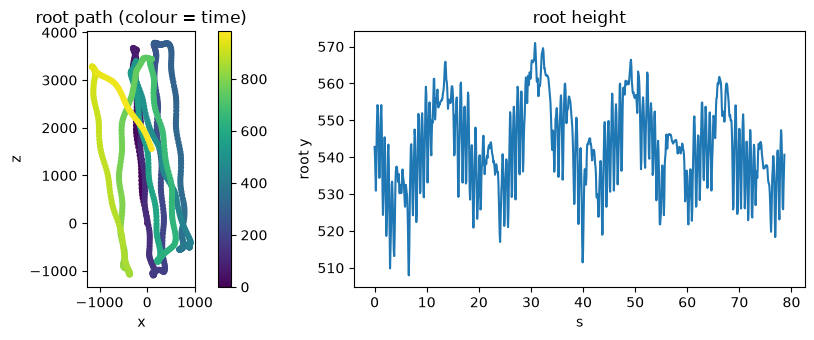

In [4]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.5))
sc = a.scatter(xyz[:, 0, 0], xyz[:, 0, 2], c=np.arange(len(xyz)), cmap="viridis", s=12)
a.set_aspect("equal"); a.set_xlabel("x"); a.set_ylabel("z"); a.set_title("root path (colour = time)"); plt.colorbar(sc, ax=a)
b.plot(np.arange(len(xyz)) / FPS, xyz[:, 0, 1]); b.set_xlabel("s"); b.set_ylabel("root y"); b.set_title("root height")
plt.tight_layout(); plt.show()

## 4. The 251-d feature vector
Slices: root (4) | ric 20x3 | rot 20x6 | vel 21x3 | contact (4). Rows = frames.

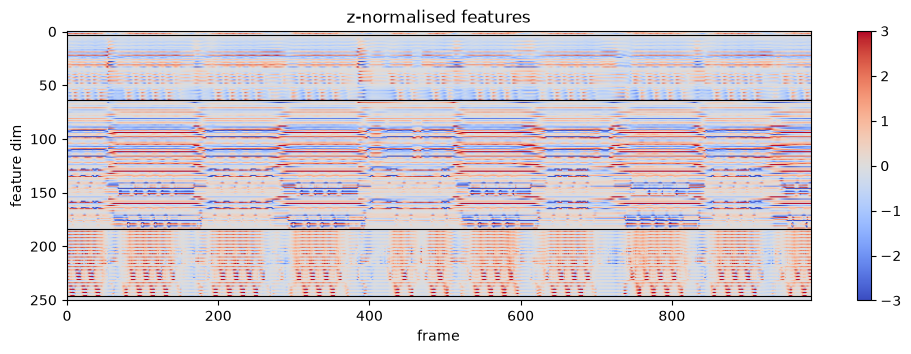

foot-contact flags (4 contact joints) per frame, first 15:
 [[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [5]:
mean, std = np.load(ROOT / "Mean.npy"), np.load(ROOT / "Std.npy")
z = (vec - mean) / std                                           # what the dataset loaders feed the model
edges = np.cumsum([0, 4, 3 * (J - 1), 6 * (J - 1), 3 * J, 4])
fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(z.T, aspect="auto", cmap="coolwarm", vmin=-3, vmax=3)
for e, n in zip(edges[1:-1], ["root", "ric", "rot", "vel"]): ax.axhline(e - .5, c="k", lw=.8)
ax.set_xlabel("frame"); ax.set_ylabel("feature dim"); ax.set_title("z-normalised features"); plt.colorbar(im); plt.show()
print("foot-contact flags (4 contact joints) per frame, first 15:\n", vec[:15, -4:].T)

## 5. Animation with `plot_3d_motion`
Same renderer `train_vae.py` uses for its `animation/` videos (KIT: `fps=12.5`, `radius=240*8`).

In [13]:
from IPython.display import Video
from utils.plot_script import plot_3d_motion

OUT = Path("visualization/renders"); OUT.mkdir(exist_ok=True)
RADIUS = 240 * 8
def render(joints, name, title):
    path = OUT / name
    plot_3d_motion(str(path), CHAIN, joints, title=title, fps=FPS, radius=RADIUS)
    return Video(str(path), embed=True, width=400)

render(xyz, f"{cid}_gt.mp4", caps[0])

## 6. VAE reconstruction check
Loads the trained VAE, reconstructs the clip and renders ground truth vs. reconstruction with `plot_3d_motion` (the same path as `make_plot_fn` in `train_vae.py`).

In [7]:
import sys
sys.path.insert(0, "."); sys.argv = sys.argv[:1]
from os.path import join as pjoin
from models.vae.model import VAE
from utils.get_opt import get_opt

NAME, CKPT = "vae_kit_v1", "net_best_val.tar"
run = Path("checkpoints/kit") / NAME
vae_opt = get_opt(str(run / "opt.txt"), torch.device("cpu"))
vae = VAE(vae_opt)
vae.load_state_dict(torch.load(run / "model" / CKPT, map_location="cpu")["vae"])
vae.eval()
mean, std = np.load(run / "meta" / "mean.npy"), np.load(run / "meta" / "std.npy")

Reading checkpoints/kit/vae_kit_v1/opt.txt


In [11]:
W = vae_opt.window_size
T = (min(len(vec), 4 * W) // W) * W or len(vec)              # crop to a multiple of the training window
x = torch.from_numpy((vec[:T] - mean) / std).float()[None]    # [1, T, 251], z-normalised
with torch.no_grad():
    pred, _ = vae(x)
rec = pred[0].numpy() * std + mean                            # back to raw features
rec_xyz = recover_from_ric(torch.from_numpy(rec).float(), J).numpy()
gt_xyz = xyz[:T]
print("feature L1:", np.abs(rec - vec[:T]).mean(), "| joint err (mm):", np.linalg.norm(rec_xyz - gt_xyz, axis=-1).mean())

feature L1: 5.756368932037843 | joint err (mm): 105.55196


In [16]:
from IPython.display import display
print("ground truth"); display(render(gt_xyz, f"{cid}_gt_crop.mp4", "ground truth"))
print("VAE reconstruction"); display(render(rec_xyz, f"{cid}_rec.mp4", "reconstruction"))

ground truth


VAE reconstruction
